# H3. Полоса дней — результаты

## Сокращения, аббревиатуры и метрики

| Как написано | Расшифровка |
|---|---|
| **H3** | гипотеза 3: короткое окно дней по продукту. |
| **окно**, полоса | дни, в которые ждут повторную покупку. |
| **покрытие** | доля строк, где настоящий день внутри окна. |
| **ширина** | правый край минус левый, среднее по строкам, в днях. |
| **сужение** | на сколько окно короче полосы ошибок: (ширина ошибок − ширина F_d) / ширина ошибок. 0,216 = короче на 21,6%. |
| **полоса ошибок** | одна длина из прошлых промахов точечного прогноза. |
| **F_d** | к дню d покупка уже случилась. Края окна: 0,1 и 0,9. |
| **h_d** | купят в день d, если раньше не купили. |
| **MLP** | сеть, слои 256 и 128, 14 логитов дней. |
| **CatBoost квантили** | две модели на 0,1 и 0,9. Не H3, порог не взят. |
| **семя 44** | генератор официальной базы 500 семей. |
| **SQLite**, `fridge_lab_v3` | эта база. Старые 200 и семя 43 в вердикт не входят. |

Гипотеза: окно по F_d накрывает день **не реже 78 из 100** и **короче** полосы ошибок **не меньше чем на 10%**.

Ноутбук **не учит** сеть. Повтор — `код/interval_h3b.py` на `fridge_lab_v3.sqlite`. Вердикт без обучения — `код/eval_h3.py`.

Порядок этапов:
1. сводная таблица порога;
2. покрытие;
3. ширина;
4. как это выглядит у молока;
5. старые постановки, не вердикт.

## Этап 1. Сводная таблица порога

Читаем `результаты/полоса.csv`. Одна строка — официальный тест.

- **ошибки** — полоса одной длины вокруг точки.
- **F_d** — окно с краёв 0,1 и 0,9 накопленной доли.
- Покрытие ≥ 0,78 и сужение ≥ 10% записаны до сборки базы семя 44.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

HERE = Path.cwd()
if not (HERE / "результаты").is_dir():
    HERE = Path(".").resolve()
RESULTS = HERE / "результаты"
DATA = HERE / "данные" / "метрики"

pd.read_csv(RESULTS / "полоса.csv")

база,строк,ошибки_покрытие,ошибки_ширина,Fd_покрытие,Fd_ширина,сужение,порог_покрытия,порог_сужения,вердикт
500 семей семя 44,237271,0.794,5.59,0.827,4.38,0.216,0.78,0.1,подтверждена


## Этап 2. Покрытие, семя 44

237 271 строка. Полоса ошибок: 0,794. Окно по F_d: **0,827**. Красная черта — порог 0,78. День внутри в 83 случаях из 100 против 79.

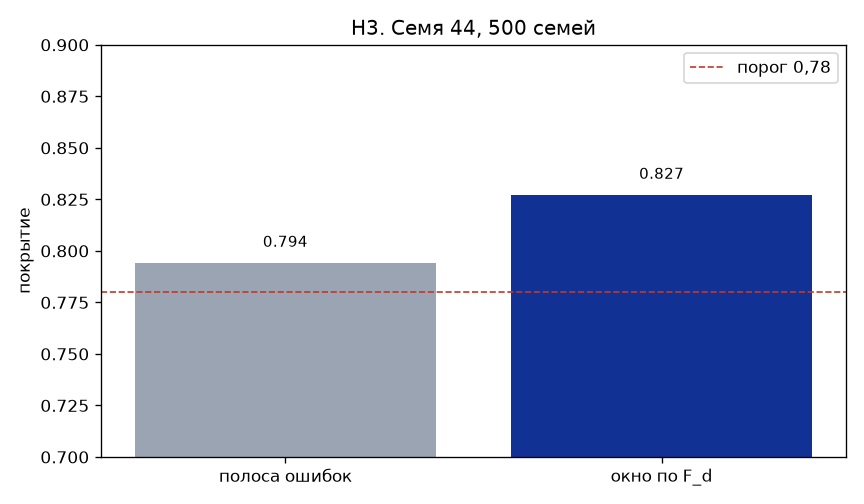

In [2]:
# Официальный тест: день внутри окна.
display(Image(str(RESULTS / 'покрытие.png'), width=720))

## Этап 3. Ширина

Ошибки: 5,59 дня. F_d: **4,38 дня**. Короче на **21,6%**, порог 10%. 4,38 — средняя длина окна, не «купят за четыре дня».

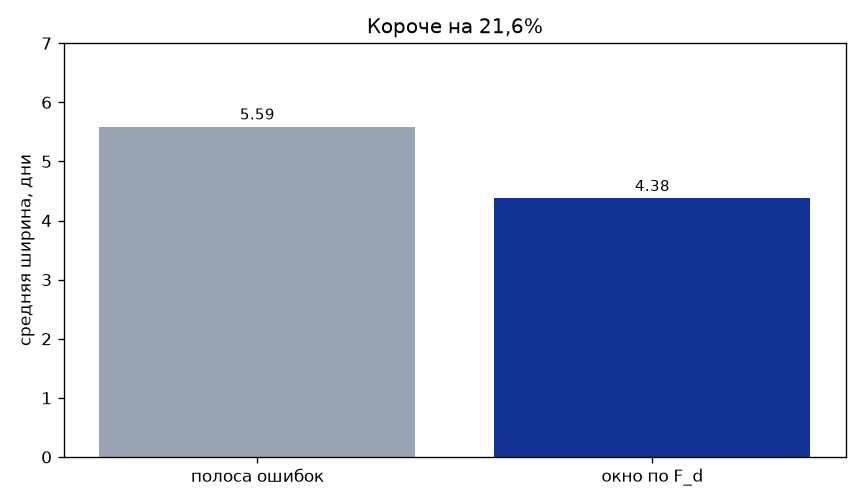

In [3]:
# Короче полосы ошибок при покрытии выше порога.
display(Image(str(RESULTS / 'ширина.png'), width=720))

## Этап 4. Молоко и гречка

Схема, не одна строка теста. Точка «6-й день» одна. Окно молока ближе, окно гречки позже. На экране — эти дни, не «в пятницу шанс 10%».

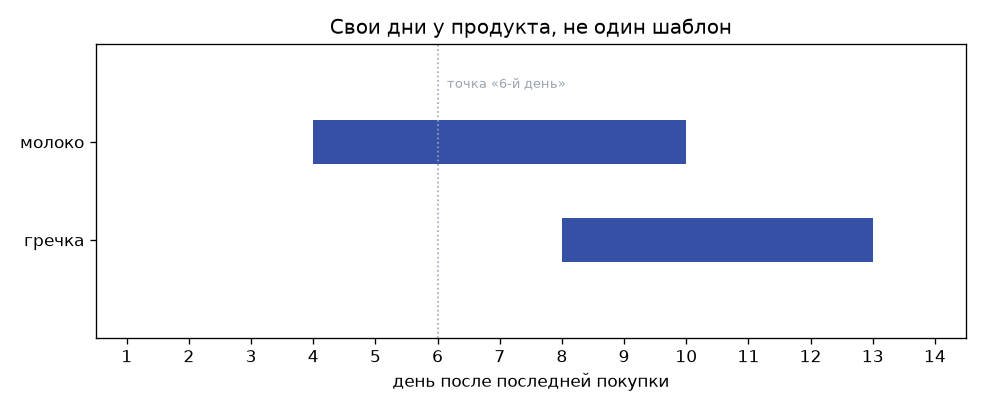

In [4]:
# Свои дни у продукта. 10% и 90% — края расчёта.
display(Image(str(RESULTS / 'пример_календаря.png'), width=720))

## Этап 5. Что не входит в вердикт

Квантили CatBoost и старый коридор 78–82% на базах семя 42 и 43 смотрели раньше. Порог H3 записан до базы семя 44. Эти строки — справка.

In [5]:
# Старые постановки. В порог H3 не входят.
pd.read_csv(DATA / "полоса_справка.csv")

постановка,база,покрытие,ширина,сужение,вердикт
квантили CatBoost 0.1 и 0.9,200 семей,0.777,5.21,0.055,не подтверждена
квантили CatBoost 0.1 и 0.9,500 семей семя 43,0.777,5.43,0.020,не подтверждена
накопленная F_d коридор 78-82%,200 семей,0.772,3.57,NaN,не подтверждена
накопленная F_d коридор 78-82%,500 семей семя 43,0.829,4.64,0.160,не подтверждена
H3 покрытие >= 0.78 и короче >= 10%,500 семей семя 44,0.827,4.38,0.216,подтверждена
